# Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data

## Acquisition

In [2]:
df = pd.read_csv('IBM-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Checking

In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


## Cleaning

In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## EDA

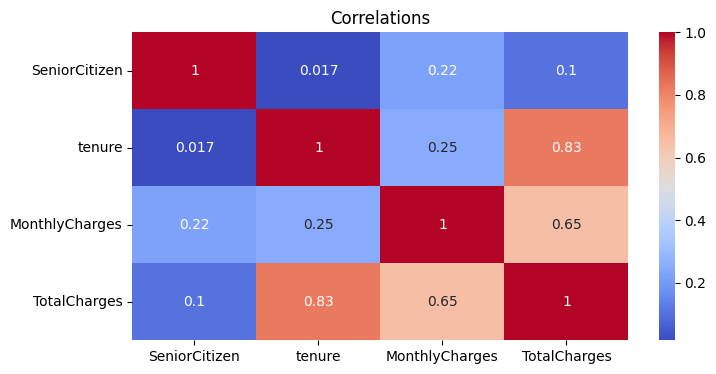

In [8]:
numeric_cols = df.select_dtypes(include=np.number)

corr = numeric_cols.corr()

plt.figure(figsize=(8, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlations")
plt.show()

In [9]:
categorical_cols = ['Contract', 'PaymentMethod', 'InternetService', 'Dependents', 'OnlineSecurity',
                       'TechSupport', 'PaperlessBilling', 'SeniorCitizen', 'Partner']

In [10]:
crosstabs = []
for col in categorical_cols:
    ct = pd.crosstab(df[col], df['Churn'], normalize="index") * 100
    crosstabs.append(ct)

df_analise = pd.concat(crosstabs, keys=categorical_cols, names=['Variable', 'Category'])

In [11]:
# Claude generated

def grouping(df):
    styles = pd.DataFrame('', index=df.index, columns=df.columns)
    grupos = df.index.get_level_values('Variable')
    for i in range(1, len(df)):
        if grupos[i] != grupos[i - 1]:
            styles.iloc[i, :] = 'border-top: 3px solid #2c3e50;'
    return styles


def high_yes_high_color(df):
    styles = pd.DataFrame('', index=df.index, columns=df.columns)
    for i, valor in enumerate(df['Yes']):
        if valor >= 50:
            styles.iloc[i, df.columns.get_loc('Yes')] = 'font-weight: bold; color: #7f0000;'
        elif valor >= 30:
            styles.iloc[i, df.columns.get_loc('Yes')] = 'font-weight: 600;'
    return styles


(
    df_analise.style
    .format("{:.1f}%")
    .background_gradient(subset=['Yes'], cmap='Reds', vmin=0, vmax=100)
    .background_gradient(subset=['No'], cmap='Greens', vmin=0, vmax=100)
    .apply(high_yes_high_color, axis=None)
    .apply(grouping, axis=None)
    .set_caption("Churn rate (%) per Variable and Category")
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2c3e50'),
            ('color', 'white'),
            ('font-weight', 'bold'),
            ('text-align', 'center'),
            ('padding', '8px 12px'),
            ('font-size', '13px'),
        ]},
        {'selector': 'caption', 'props': [
            ('font-size', '16px'),
            ('font-weight', 'bold'),
            ('color', '#2c3e50'),
            ('padding', '10px'),
            ('caption-side', 'top'),
        ]},
        {'selector': 'td', 'props': [
            ('text-align', 'center'),
            ('padding', '6px 12px'),
            ('font-size', '13px'),
        ]},
        {'selector': 'th.row_heading.level0', 'props': [
            ('background-color', '#34495e'),
            ('color', 'white'),
            ('text-align', 'left'),
            ('font-weight', 'bold'),
        ]},
        {'selector': 'th.row_heading.level1', 'props': [
            ('background-color', '#ecf0f1'),
            ('color', '#2c3e50'),
            ('text-align', 'left'),
        ]},
    ])
)

# Data splitting

## variables splitting

In [12]:
df = df.drop(columns=["customerID"], errors="ignore")

In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [14]:
df = df.dropna(subset=["TotalCharges"]).copy()

In [15]:
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

In [16]:
X.shape

(7032, 19)

In [17]:
print(y.shape)
print()
print(y.value_counts())

(7032,)

Churn
0    5163
1    1869
Name: count, dtype: int64


## train_test_split

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5625, 19)
(1407, 19)


## Enconding categorical columns

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [20]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

In [21]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [22]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Balancing

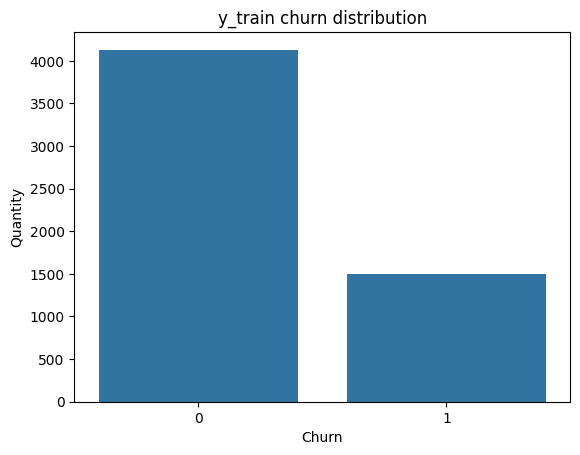

Churn
0    73.42
1    26.58
Name: proportion, dtype: float64


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=y_train)

plt.title("y_train churn distribution")
plt.xlabel("Churn")
plt.ylabel("Quantity")
plt.show()

print(
    y_train.value_counts(normalize=True).mul(100).round(2)
)

In [25]:
from sklearn.linear_model import LogisticRegression

## Approach 0: No treatment

In [26]:
# this model will serve as baseline for future comparisons
model_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

model_baseline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

## Approach 1: Class weights

In [27]:
model_weighted = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

model_weighted.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

## Approach 2: SMOTE

In [28]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import OrdinalEncoder

In [29]:
preprocessor_smote = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_features)
])

In [30]:
categorical_indices = list(
    range(len(numeric_features),
          len(numeric_features) + len(categorical_features))
)

In [31]:
model_smote = ImbPipeline([
    ("preprocessor", preprocessor_smote),
    ("smote", SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ("onehot", ColumnTransformer([
        ("num", "passthrough", list(range(len(numeric_features)))),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_indices)
    ])),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

model_smote.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ordinal',
                                                                   OrdinalEncoder(handle_unknown='use_encoded...
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('smote',
                 SMOTENC(categorical_features=[4, 5, 6, 7, 8, 9, 10, 11, 12, 13,
                                               14, 15, 16, 17, 18],
                         random_state=42)),
                ('onehot',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  [0, 1, 2, 3]),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  [4, 5, 6, 7, 8, 9, 10, 11, 12,
                                                   13, 14, 15, 16, 17, 18])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

# Model Training

In [32]:
# class predictions
y_pred_baseline = model_baseline.predict(X_test)
y_pred_weighted = model_weighted.predict(X_test)
y_pred_smote = model_smote.predict(X_test)

# churn probabilities
y_prob_baseline = model_baseline.predict_proba(X_test)[:, 1]
y_prob_weighted = model_weighted.predict_proba(X_test)[:, 1]
y_prob_smote = model_smote.predict_proba(X_test)[:, 1]

## Performance reviews

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [34]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

In [35]:
baseline_eval = evaluate_model("Baseline", y_test, y_pred_baseline, y_prob_baseline)

In [36]:
weighted_eval = evaluate_model("Class Weight", y_test, y_pred_weighted, y_prob_weighted)

In [37]:
smote_eval = evaluate_model("SMOTENC", y_test, y_pred_smote, y_prob_smote)

In [38]:
results_df = pd.DataFrame([baseline_eval, weighted_eval, smote_eval])
results_df.set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Baseline,0.804,0.648,0.572,0.608,0.836
Class Weight,0.726,0.490,0.797,0.607,0.835
SMOTENC,0.740,0.507,0.762,0.609,0.829


## Confusion Matrices

### Baseline

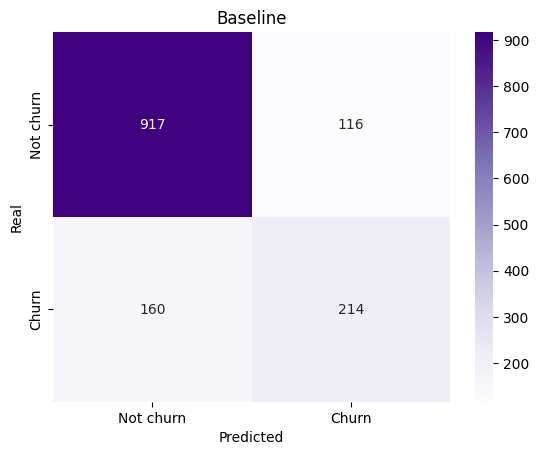

In [39]:
cm = confusion_matrix(y_test, y_pred_baseline)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Not churn", "Churn"],
    yticklabels=["Not churn", "Churn"]
)

plt.title("Baseline")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

### Class weights

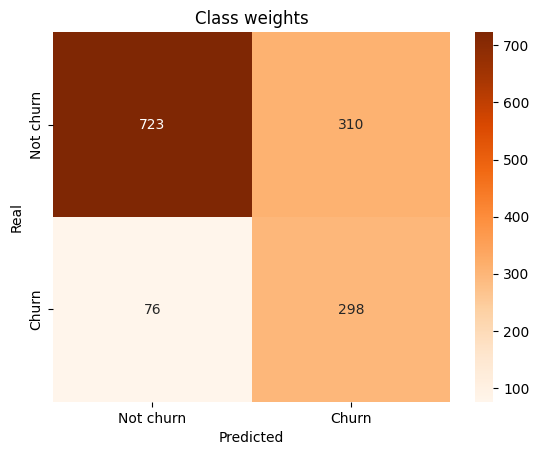

In [40]:
cm = confusion_matrix(y_test, y_pred_weighted)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Not churn", "Churn"],
    yticklabels=["Not churn", "Churn"]
)

plt.title("Class weights")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

### SMOTE

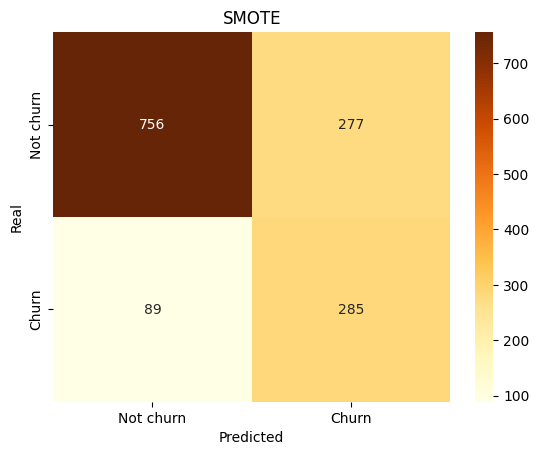

In [41]:
cm = confusion_matrix(y_test, y_pred_smote)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlOrBr",
    xticklabels=["Not churn", "Churn"],
    yticklabels=["Not churn", "Churn"]
)

plt.title("SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

# Other Models

## Random Forest

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [43]:
rf_weighted = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_weighted.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [44]:
# Class predictions
y_pred_rf = rf_weighted.predict(X_test)

# Churn probabilities
y_prob_rf = rf_weighted.predict_proba(X_test)[:, 1]

## XGBoost

In [45]:
from xgboost import XGBClassifier

In [46]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Not churn:", negative_count)
print("Churn:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 3))

Not churn: 4130
Churn: 1495
scale_pos_weight: 2.763


In [47]:
xgb_weighted = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_weighted.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [48]:
y_pred_xgboost = xgb_weighted.predict(X_test)

y_prob_xgboost = xgb_weighted.predict_proba(X_test)[:, 1]

## Comparisons

In [49]:
rf_eval = evaluate_model("Random Forest", y_test, y_pred_rf, y_prob_rf)

In [50]:
xgboost_eval = evaluate_model("XGBoost", y_test, y_pred_xgboost, y_prob_xgboost)

In [51]:
new_results_df = pd.DataFrame([weighted_eval, rf_eval, xgboost_eval])
new_results_df.set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Class Weight,0.726,0.490,0.797,0.607,0.835
Random Forest,0.784,0.622,0.476,0.539,0.812
XGBoost,0.736,0.502,0.765,0.606,0.832


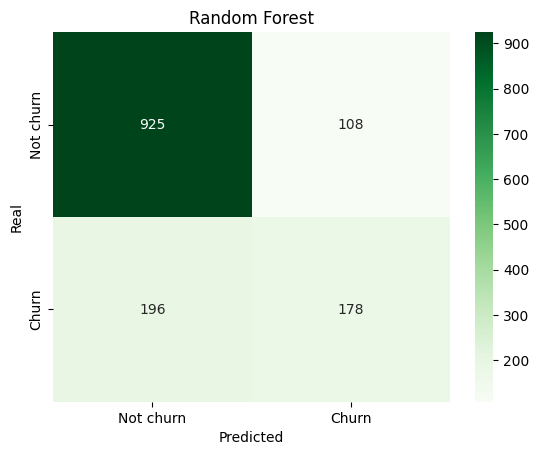

In [52]:
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not churn", "Churn"],
    yticklabels=["Not churn", "Churn"]
)

plt.title("Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

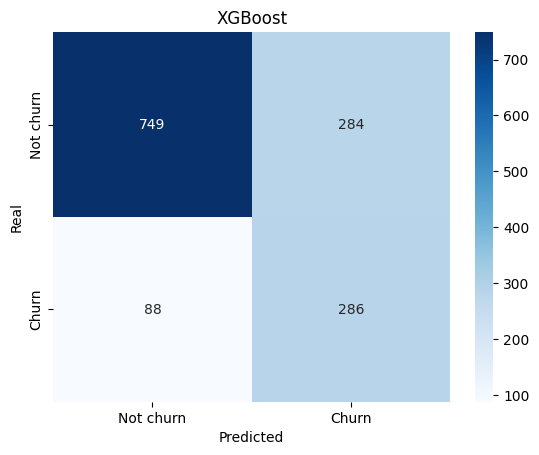

In [53]:
cm = confusion_matrix(y_test, y_pred_xgboost)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not churn", "Churn"],
    yticklabels=["Not churn", "Churn"]
)

plt.title("XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

## Features review

### Random Forest

In [54]:
rf_classifier = rf_weighted.named_steps["classifier"]

feature_names = (
    rf_weighted
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance.head(15))

                                Feature  Importance
3                     num__TotalCharges    0.141739
1                           num__tenure    0.129514
2                   num__MonthlyCharges    0.123187
36         cat__Contract_Month-to-month    0.075278
38               cat__Contract_Two year    0.037938
18               cat__OnlineSecurity_No    0.037016
27                  cat__TechSupport_No    0.030369
43  cat__PaymentMethod_Electronic check    0.029360
16     cat__InternetService_Fiber optic    0.025750
21                 cat__OnlineBackup_No    0.017357
0                    num__SeniorCitizen    0.016369
4                    cat__gender_Female    0.016335
5                      cat__gender_Male    0.016262
37               cat__Contract_One year    0.014838
39             cat__PaperlessBilling_No    0.014733


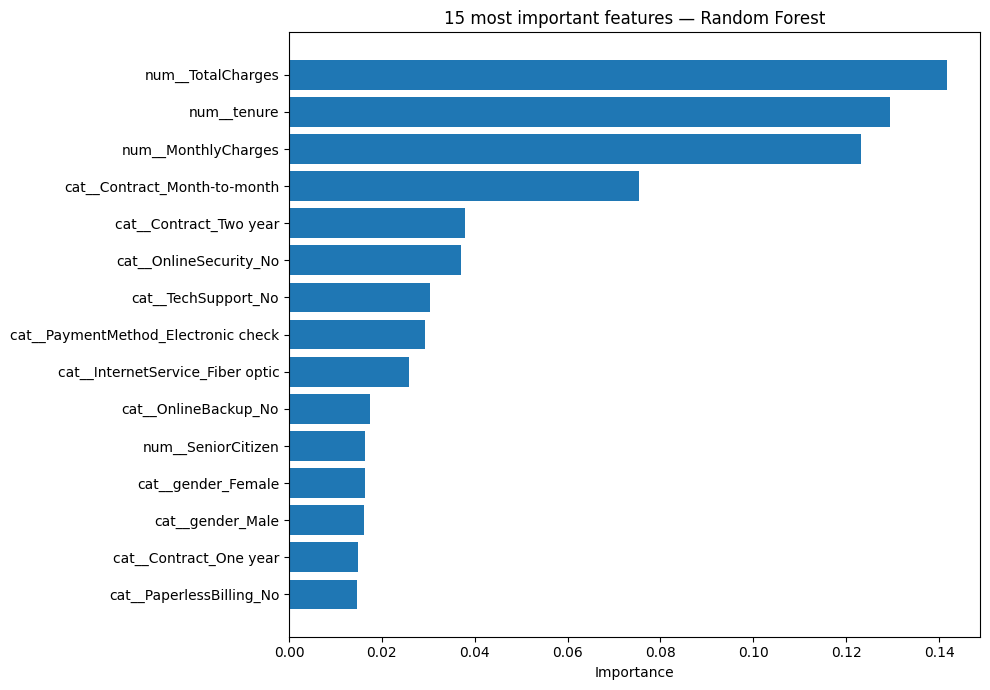

In [55]:
top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("15 most important features — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### XGBoost

In [56]:
xgb_classifier = xgb_weighted.named_steps["classifier"]

feature_names = (
    xgb_weighted
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance.head(15))

                                Feature  Importance
36         cat__Contract_Month-to-month    0.301211
18               cat__OnlineSecurity_No    0.123459
16     cat__InternetService_Fiber optic    0.073422
15             cat__InternetService_DSL    0.042244
27                  cat__TechSupport_No    0.039802
38               cat__Contract_Two year    0.036810
43  cat__PaymentMethod_Electronic check    0.020687
37               cat__Contract_One year    0.020547
35             cat__StreamingMovies_Yes    0.019109
1                           num__tenure    0.017127
32                 cat__StreamingTV_Yes    0.016522
17              cat__InternetService_No    0.015051
11                cat__PhoneService_Yes    0.014630
10                 cat__PhoneService_No    0.013733
40            cat__PaperlessBilling_Yes    0.013626


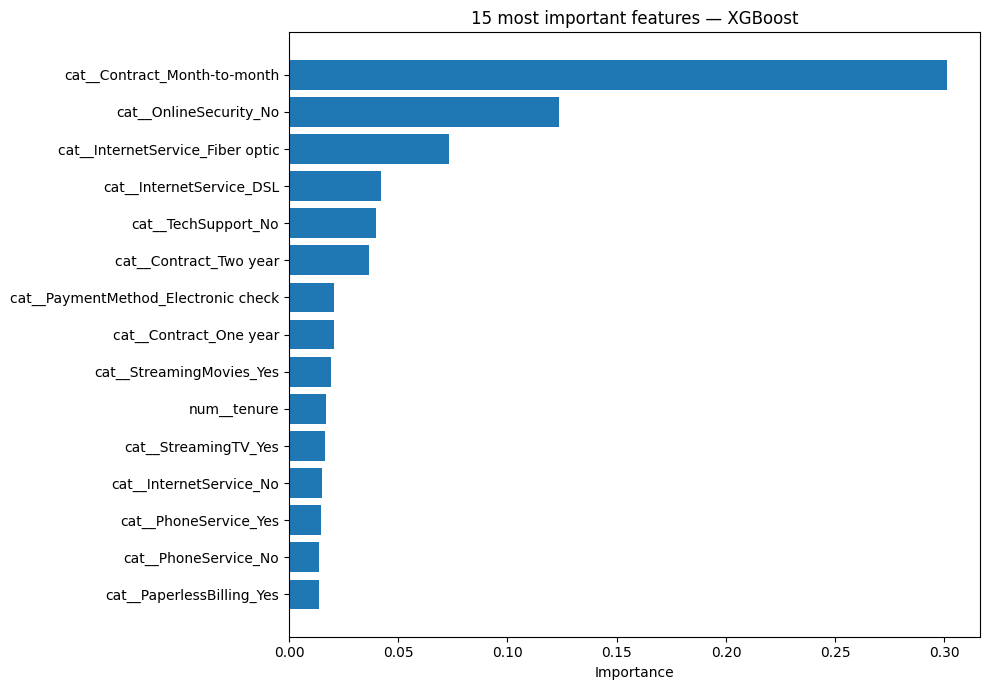

In [57]:
top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("15 most important features — XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()